# 신용카드 사기 거래 탐지(Fraud Detection)

## 프로젝트 목표
신용카드 거래 데이터를 이용해 정상 거래(`Class=0`)와 사기 거래(`Class=1`)를 분류
- 사기 거래는 전체 데이터에서 매우 적은 **불균형 데이터**
- 정확도(Accuracy)만으로 모델을 평가하면 사기 거래를 놓치는 문제를 발견하기 어려움
- 따라서 사기 거래를 얼마나 잘 찾아내는지 확인하는 **재현율(Recall)**을 주요 평가 지표로 사용



## 1. 라이브러리 불러오기

In [1]:
# 데이터 처리 및 시각화 라이브러리
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 데이터 분리 및 교차검증
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

# 데이터 전처리 및 파이프라인
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# 분류 알고리즘
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
    ExtraTreesClassifier
)

# 모델 평가 지표
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.precision", 3)

# 그래프 기본 설정
sns.set_theme(style="whitegrid")

## 2. 데이터 불러오기

In [2]:
# 현재 작업 폴더에서 데이터 파일 찾기
if os.path.exists("creditcard_sample.csv"):
    data_path = "creditcard_sample.csv"
elif os.path.exists("creditcard.csv"):
    data_path = "creditcard.csv"
else:
    raise FileNotFoundError(
        "creditcard_sample.csv 또는 creditcard.csv 파일을 "
        "노트북과 같은 폴더에 저장해 주세요."
    )

dataset = pd.read_csv(data_path)

print("불러온 파일:", data_path)
print("데이터 크기:", dataset.shape)
display(dataset.head())

불러온 파일: creditcard_sample.csv
데이터 크기: (99999, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.360,-0.073,2.536,1.378,-0.338,0.462,0.240,0.099,0.364,0.091,-0.552,-0.618,-0.991,-0.311,1.468,-0.470,0.208,0.026,0.404,0.251,-0.018,0.278,-0.110,0.067,0.129,-0.189,0.134,-0.021,149.62,0
1,0,1.192,0.266,0.166,0.448,0.060,-0.082,-0.079,0.085,-0.255,-0.167,1.613,1.065,0.489,-0.144,0.636,0.464,-0.115,-0.183,-0.146,-0.069,-0.226,-0.639,0.101,-0.340,0.167,0.126,-0.009,0.015,2.69,0
2,1,-1.358,-1.340,1.773,0.380,-0.503,1.800,0.791,0.248,-1.515,0.208,0.625,0.066,0.717,-0.166,2.346,-2.890,1.110,-0.121,-2.262,0.525,0.248,0.772,0.909,-0.689,-0.328,-0.139,-0.055,-0.060,378.66,0
3,1,-0.966,-0.185,1.793,-0.863,-0.010,1.247,0.238,0.377,-1.387,-0.055,-0.226,0.178,0.508,-0.288,-0.631,-1.060,-0.684,1.966,-1.233,-0.208,-0.108,0.005,-0.190,-1.176,0.647,-0.222,0.063,0.061,123.50,0
4,2,-1.158,0.878,1.549,0.403,-0.407,0.096,0.593,-0.271,0.818,0.753,-0.823,0.538,1.346,-1.120,0.175,-0.451,-0.237,-0.038,0.803,0.409,-0.009,0.798,-0.137,0.141,-0.206,0.502,0.219,0.215,69.99,0


## 3. 데이터 구조 및 기초 통계 확인


In [3]:
# 실제 컬럼명과 데이터 타입 확인
print("컬럼 목록:")
print(dataset.columns.tolist())

print("\n데이터 타입 및 결측치 정보:")
dataset.info()

print("\n기술통계량:")
display(dataset.describe(include="all"))

컬럼 목록:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

데이터 타입 및 결측치 정보:
<class 'pandas.DataFrame'>
RangeIndex: 99999 entries, 0 to 99998
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    99999 non-null  int64  
 1   V1      99999 non-null  float64
 2   V2      99999 non-null  float64
 3   V3      99999 non-null  float64
 4   V4      99999 non-null  float64
 5   V5      99999 non-null  float64
 6   V6      99999 non-null  float64
 7   V7      99999 non-null  float64
 8   V8      99999 non-null  float64
 9   V9      99999 non-null  float64
 10  V10     99999 non-null  float64
 11  V11     99999 non-null  float64
 12  V12     99999 non-null  float64
 13  V13     99999 non-null  float64
 14  V14     99999 non-null  float64
 15  V15     99999 non-null  floa

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,99999.000,1.000e+05,99999.000,99999.000,99999.000
mean,42432.982,-0.262,-0.032,0.676,0.163,-0.279,0.094,-0.109,0.056,-0.047,-0.023,0.250,-0.066,0.008,0.060,0.193,-0.008,0.058,-0.092,-0.022,0.045,-0.031,-0.109,-0.037,0.009,0.132,0.027,6.058e-04,0.002,97.962,0.002
std,17044.825,1.859,1.657,1.323,1.349,1.356,1.301,1.211,1.208,1.121,1.070,1.067,1.113,1.038,0.966,0.930,0.899,0.943,0.846,0.817,0.759,0.719,0.634,0.633,0.595,0.441,0.495,3.937e-01,0.325,264.624,0.047
min,0.000,-56.408,-72.716,-33.681,-5.173,-42.148,-26.161,-31.765,-73.217,-9.284,-18.271,-4.050,-17.769,-5.792,-19.214,-4.153,-13.563,-25.163,-9.499,-7.214,-21.025,-34.830,-10.933,-44.808,-2.837,-10.295,-2.534,-9.391e+00,-9.618,0.000,0.000
25%,33471.500,-1.028,-0.599,0.177,-0.711,-0.899,-0.648,-0.600,-0.137,-0.699,-0.496,-0.524,-0.483,-0.678,-0.333,-0.358,-0.481,-0.401,-0.562,-0.516,-0.169,-0.225,-0.531,-0.176,-0.324,-0.132,-0.325,-6.253e-02,-0.005,7.570,0.000
50%,44299.000,-0.261,0.078,0.754,0.193,-0.314,-0.157,-0.069,0.074,-0.119,-0.095,0.181,0.113,-0.008,0.078,0.300,0.067,-0.001,-0.087,-0.026,-0.025,-0.058,-0.084,-0.049,0.065,0.170,-0.070,9.832e-03,0.023,26.310,0.000
75%,55851.000,1.153,0.736,1.376,1.032,0.250,0.486,0.415,0.361,0.558,0.439,1.065,0.624,0.684,0.491,0.865,0.537,0.456,0.388,0.480,0.171,0.119,0.308,0.082,0.406,0.420,0.301,8.302e-02,0.077,89.000,0.000
max,67374.000,1.960,18.902,4.226,16.716,34.802,22.529,36.677,20.007,10.393,13.249,12.019,7.848,4.465,10.527,5.785,6.099,9.254,5.041,5.228,39.421,22.615,10.503,19.003,4.014,5.542,3.517,1.215e+01,33.848,19656.530,1.000


In [4]:
# 사기 여부 컬럼이 있는지 확인
if "Class" not in dataset.columns:
    raise KeyError(
        "데이터에 'Class' 컬럼이 없습니다. "
        "실제 컬럼명을 확인하고 사기 여부 컬럼을 지정해 주세요."
    )

# 정상 거래와 사기 거래의 건수 확인
class_names = {0: "정상 거래", 1: "사기 거래"}
class_counts = dataset["Class"].value_counts().sort_index()
print(class_counts.rename(index=class_names))

print("\n클래스별 비율(%):")
print((dataset["Class"].value_counts(normalize=True) * 100).round(3))

Class
정상 거래    99776
사기 거래      223
Name: count, dtype: int64

클래스별 비율(%):
Class
0    99.777
1     0.223
Name: proportion, dtype: float64


## 4. 탐색적 데이터 분석(EDA)

### 4.1 클래스 불균형 확인


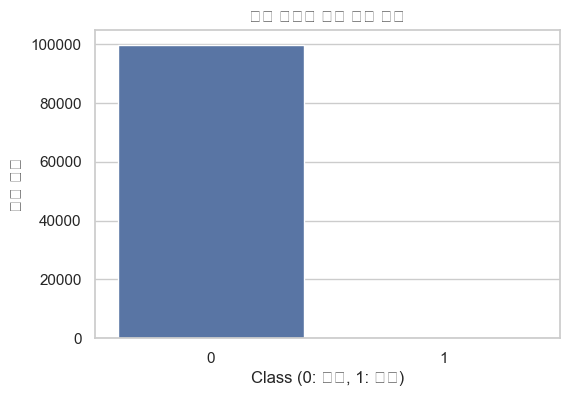

In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(data=dataset, x="Class")
plt.title("정상 거래와 사기 거래 건수")
plt.xlabel("Class (0: 정상, 1: 사기)")
plt.ylabel("거래 건수")
plt.show()

### 4.2 수치형 변수의 분포



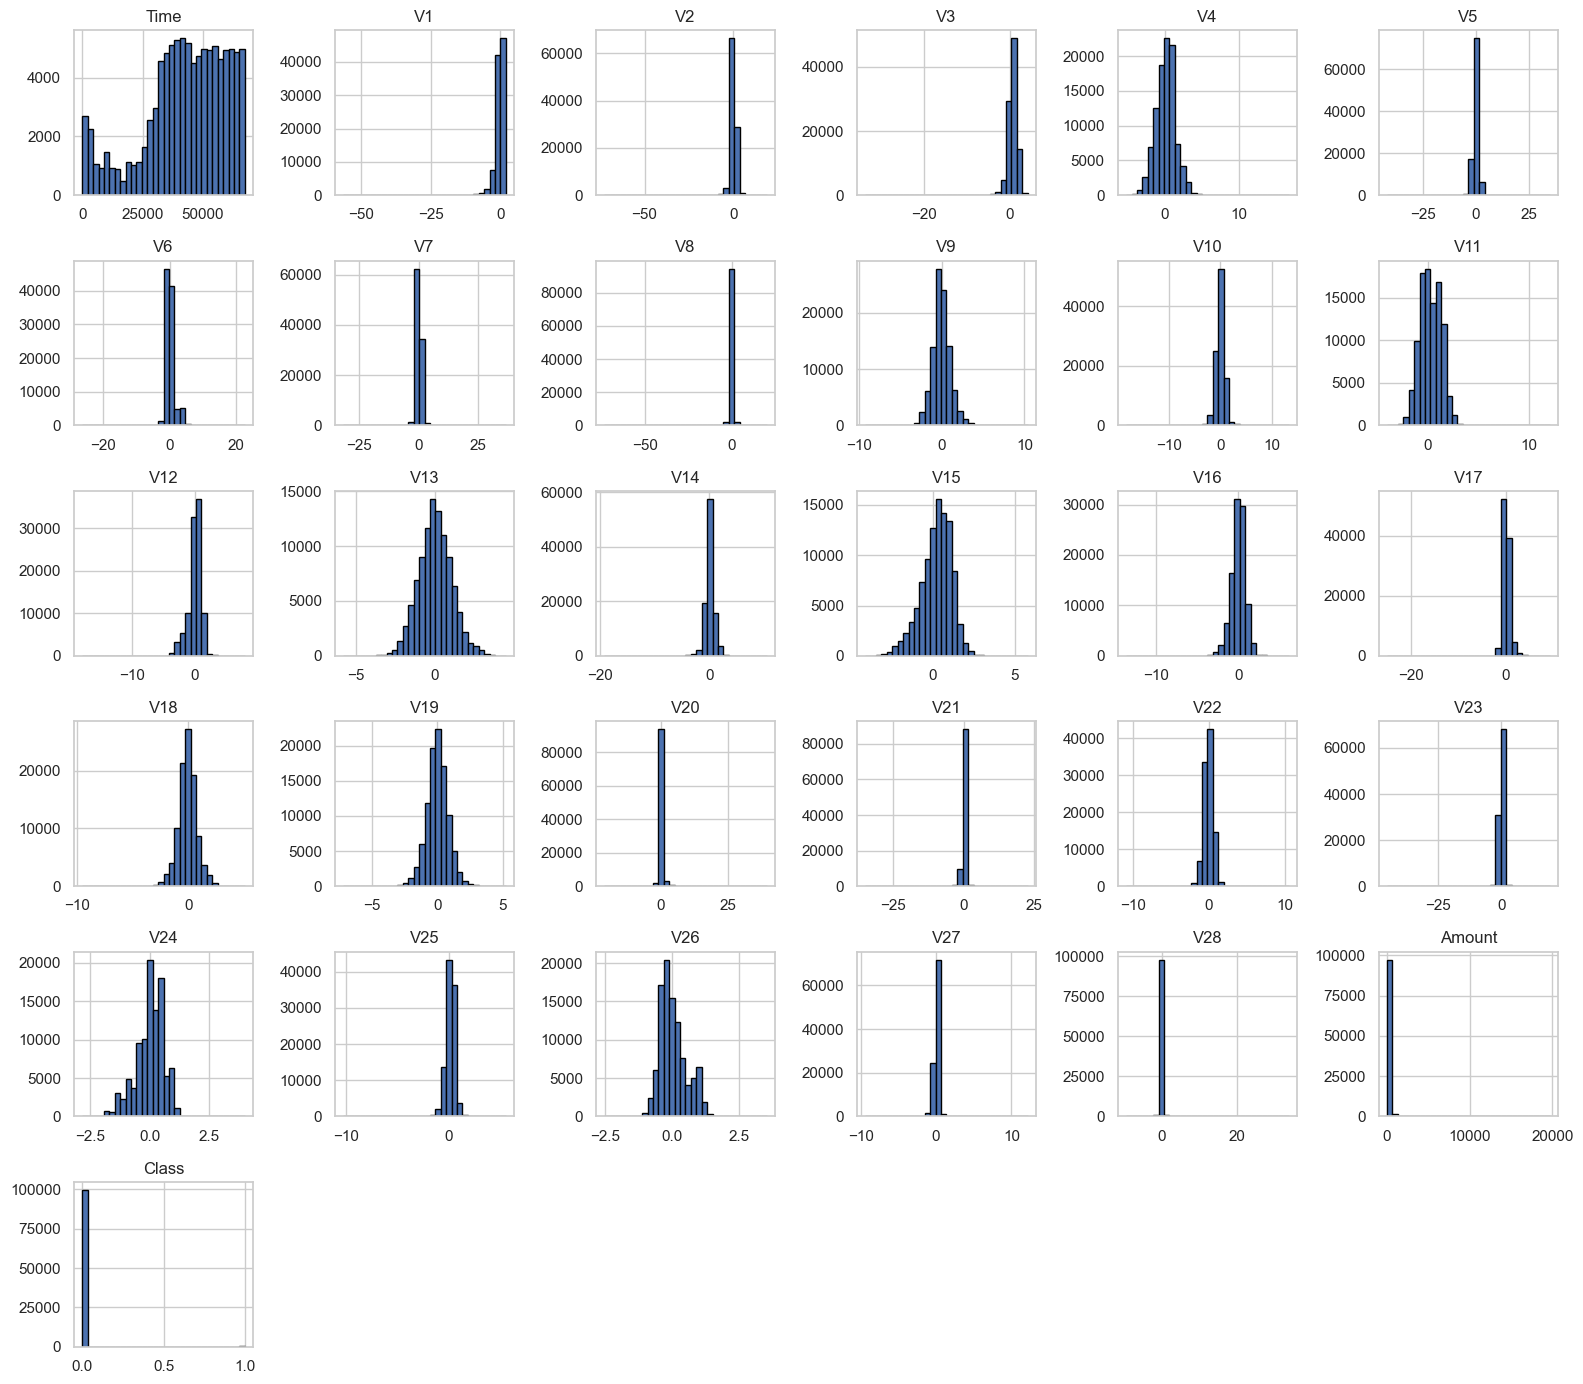

In [6]:
numeric_columns = dataset.select_dtypes(include="number").columns
dataset[numeric_columns].hist(
    figsize=(16, 14),
    bins=30,
    edgecolor="black"
)
plt.tight_layout()
plt.show()

### 4.3 상관관계 분석


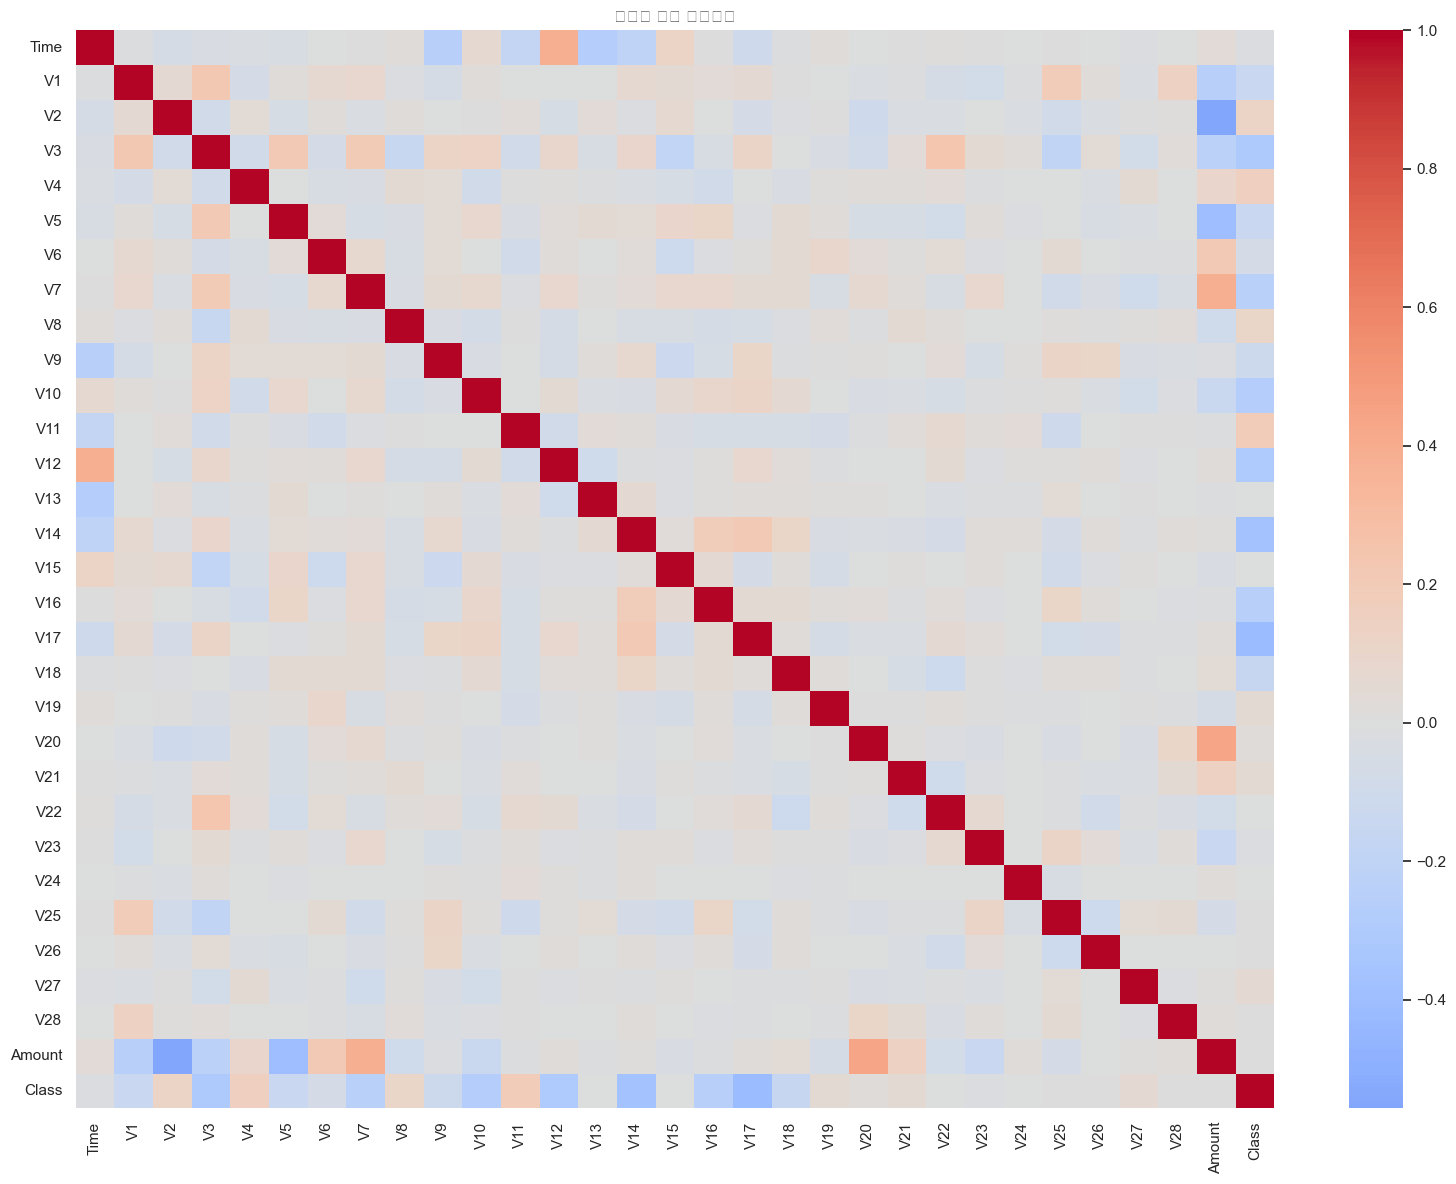

In [7]:
correlation = dataset.corr(numeric_only=True)

plt.figure(figsize=(16, 12))
sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=False
)
plt.title("수치형 변수 상관관계")
plt.tight_layout()
plt.show()

## 5. 데이터 전처리 및 특성 선택

### 5.1 결측치 확인

In [8]:
missing_counts = dataset.isnull().sum()
print("컬럼별 결측치 개수:")
print(missing_counts[missing_counts > 0])

print("\n결측치가 하나라도 있는가?", dataset.isnull().values.any())

컬럼별 결측치 개수:
Series([], dtype: int64)

결측치가 하나라도 있는가? False


### 5.2 입력 변수(X)와 정답 변수(y) 분리

`Class`는 예측할 정답 변수입니다. 나머지 컬럼을 입력 변수로 사용합니다. 데이터 누수를 방지하기 위해 학습 데이터와 검증 데이터를 먼저 분리합니다.

In [9]:
# 입력 변수와 정답 변수 분리
X = dataset.drop(columns=["Class"])
y = dataset["Class"].astype(int)

# 학습 데이터와 검증 데이터 분리
# stratify=y를 사용해 두 데이터에 정상/사기 비율이 비슷하게 유지되도록 함
X_train, X_validation, y_train, y_validation = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=7,
    stratify=y
)

print("학습 데이터:", X_train.shape)
print("검증 데이터:", X_validation.shape)
print("\n학습 데이터 클래스 비율:")
print(y_train.value_counts(normalize=True).round(4))
print("\n검증 데이터 클래스 비율:")
print(y_validation.value_counts(normalize=True).round(4))

학습 데이터: (79999, 30)
검증 데이터: (20000, 30)

학습 데이터 클래스 비율:
Class
0    0.998
1    0.002
Name: proportion, dtype: float64

검증 데이터 클래스 비율:
Class
0    0.998
1    0.002
Name: proportion, dtype: float64


### 5.3 특성 중요도 탐색



In [10]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif

# 학습 데이터만 사용해 특성 점수 계산
selector = SelectKBest(
    score_func=mutual_info_classif,
    k=min(10, X_train.shape[1])
)
selector.fit(X_train, y_train)

feature_scores = pd.DataFrame({
    "특성": X_train.columns,
    "점수": selector.scores_
}).sort_values("점수", ascending=False)

display(feature_scores.head(10))

,특성,점수
17,V17,0.011
14,V14,0.011
12,V12,0.010
10,V10,0.010
11,V11,0.009
16,V16,0.008
4,V4,0.007
3,V3,0.007
18,V18,0.007
9,V9,0.006


## 6. 모델 학습 및 교차검증

### 6.1 평가 지표 선택



In [11]:
# 교차검증 설정
num_folds = 5
seed = 7
scoring = "recall"

kfold = StratifiedKFold(
    n_splits=num_folds,
    shuffle=True,
    random_state=seed
)

### 6.2 여러 분류 모델 비교


In [12]:
# 모델 목록 구성
models = [
    ("LR", Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
    ])),
    ("LDA", Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearDiscriminantAnalysis())
    ])),
    ("KNN", Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ])),
    ("CART", DecisionTreeClassifier(
        random_state=seed,
        class_weight="balanced"
    )),
    ("NB", GaussianNB()),
    ("MLP", Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(32, 16),
            max_iter=300,
            random_state=seed
        ))
    ])),
    ("AB", AdaBoostClassifier(random_state=seed)),
    ("GBM", GradientBoostingClassifier(random_state=seed)),
    ("RF", RandomForestClassifier(
        n_estimators=100,
        random_state=seed,
        class_weight="balanced",
        n_jobs=-1
    )),
    ("ET", ExtraTreesClassifier(
        n_estimators=100,
        random_state=seed,
        class_weight="balanced",
        n_jobs=-1
    ))
]

In [13]:
# 각 모델의 교차검증 재현율 계산
results = []
names = []

for name, model in models:
    cv_results = cross_val_score(
        model,
        X_train,
        y_train,
        cv=kfold,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    results.append(cv_results)
    names.append(name)

    print(
        f"{name}: 평균 재현율 {cv_results.mean():.4f} "
        f"(표준편차 {cv_results.std():.4f})"
    )

LR: 평균 재현율 0.8927 (표준편차 0.0555)
LDA: 평균 재현율 0.7524 (표준편차 0.0728)
KNN: 평균 재현율 0.7914 (표준편차 0.0741)
CART: 평균 재현율 0.7127 (표준편차 0.0727)
NB: 평균 재현율 0.8308 (표준편차 0.0607)
MLP: 평균 재현율 0.8138 (표준편차 0.0764)
AB: 평균 재현율 0.7011 (표준편차 0.1307)
GBM: 평균 재현율 0.6337 (표준편차 0.1099)
RF: 평균 재현율 0.7517 (표준편차 0.0908)
ET: 평균 재현율 0.7857 (표준편차 0.0880)


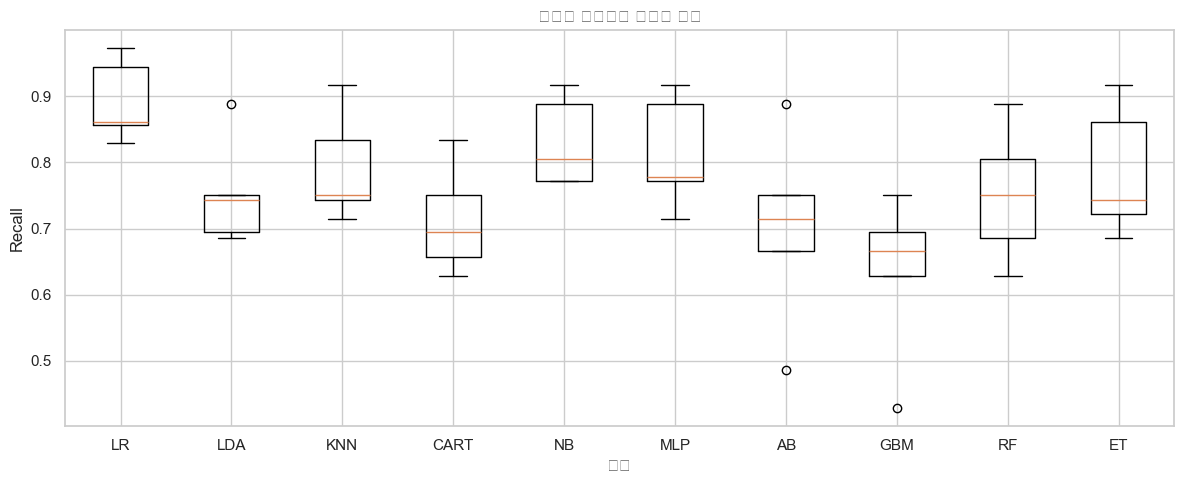

In [14]:
# 모델별 교차검증 결과를 상자그림으로 비교
plt.figure(figsize=(12, 5))
plt.boxplot(results, tick_labels=names)
plt.title("모델별 교차검증 재현율 비교")
plt.xlabel("모델")
plt.ylabel("Recall")
plt.tight_layout()
plt.show()

## 7. 원본 학습 데이터로 모델 평가


In [15]:
# 결정트리 모델 학습
baseline_model = DecisionTreeClassifier(
    random_state=seed,
    class_weight="balanced"
)
baseline_model.fit(X_train, y_train)

# 검증 데이터 예측
baseline_predictions = baseline_model.predict(X_validation)

print("정확도:", accuracy_score(y_validation, baseline_predictions))
print("정밀도:", precision_score(y_validation, baseline_predictions, zero_division=0))
print("재현율:", recall_score(y_validation, baseline_predictions, zero_division=0))
print("F1 점수:", f1_score(y_validation, baseline_predictions, zero_division=0))
print("\n분류 보고서:")
print(classification_report(
    y_validation,
    baseline_predictions,
    target_names=["정상 거래", "사기 거래"],
    zero_division=0
))

정확도: 0.9994
정밀도: 0.8367346938775511
재현율: 0.9111111111111111
F1 점수: 0.8723404255319149

분류 보고서:
              precision    recall  f1-score   support

       정상 거래       1.00      1.00      1.00     19955
       사기 거래       0.84      0.91      0.87        45

    accuracy                           1.00     20000
   macro avg       0.92      0.96      0.94     20000
weighted avg       1.00      1.00      1.00     20000



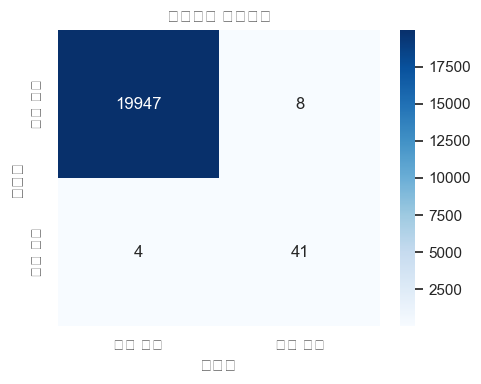

In [16]:
# 혼동행렬 시각화
cm = confusion_matrix(y_validation, baseline_predictions)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["정상 예측", "사기 예측"],
    yticklabels=["실제 정상", "실제 사기"]
)
plt.title("결정트리 혼동행렬")
plt.xlabel("예측값")
plt.ylabel("실제값")
plt.tight_layout()
plt.show()

## 8. 랜덤 언더샘플링(Random Under-Sampling)


In [17]:
# 학습 데이터와 정답을 하나의 데이터프레임으로 결합
train_df = X_train.copy()
train_df["Class"] = y_train

# 학습 데이터에서 클래스별 건수 확인
print("언더샘플링 전 클래스별 건수:")
print(train_df["Class"].value_counts())

# 학습 데이터에서 더 적은 클래스의 건수에 맞춰 정상 거래를 추출
class_counts = train_df["Class"].value_counts()
minority_count = class_counts.min()

fraud_train = train_df[train_df["Class"] == 1]
normal_train = train_df[train_df["Class"] == 0]

# 두 클래스 중 다수 클래스에서 소수 클래스 수만큼 무작위 추출
if len(fraud_train) < len(normal_train):
    normal_sample = normal_train.sample(
        n=minority_count,
        random_state=seed
    )
    balanced_train = pd.concat([fraud_train, normal_sample])
else:
    fraud_sample = fraud_train.sample(
        n=minority_count,
        random_state=seed
    )
    balanced_train = pd.concat([normal_train, fraud_sample])

# 행 순서를 무작위로 섞기
balanced_train = balanced_train.sample(
    frac=1,
    random_state=seed
).reset_index(drop=True)

# 언더샘플링된 학습 데이터 분리
X_train_balanced = balanced_train.drop(columns=["Class"])
y_train_balanced = balanced_train["Class"]

print("\n언더샘플링 후 클래스별 건수:")
print(y_train_balanced.value_counts())

언더샘플링 전 클래스별 건수:
Class
0    79821
1      178
Name: count, dtype: int64

언더샘플링 후 클래스별 건수:
Class
0    178
1    178
Name: count, dtype: int64


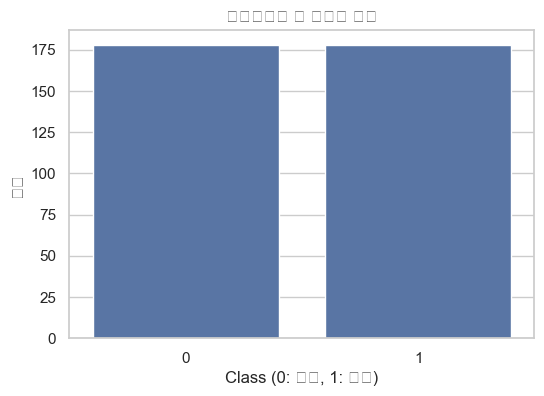

In [18]:
# 언더샘플링 후 클래스 비율 시각화
plt.figure(figsize=(6, 4))
sns.countplot(data=balanced_train, x="Class")
plt.title("언더샘플링 후 클래스 분포")
plt.xlabel("Class (0: 정상, 1: 사기)")
plt.ylabel("건수")
plt.show()

## 9. 균형 학습 데이터에서 모델 비교



In [19]:
# 언더샘플링 데이터용 교차검증 설정
balanced_kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=seed
)

balanced_models = [
    ("LR", Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ])),
    ("LDA", Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearDiscriminantAnalysis())
    ])),
    ("KNN", Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ])),
    ("CART", DecisionTreeClassifier(random_state=seed)),
    ("NB", GaussianNB()),
    ("SVM", Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC())
    ])),
    ("MLP", Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(32, 16),
            max_iter=300,
            random_state=seed
        ))
    ])),
    ("AB", AdaBoostClassifier(random_state=seed)),
    ("GBM", GradientBoostingClassifier(random_state=seed)),
    ("RF", RandomForestClassifier(
        n_estimators=100,
        random_state=seed,
        n_jobs=-1
    )),
    ("ET", ExtraTreesClassifier(
        n_estimators=100,
        random_state=seed,
        n_jobs=-1
    ))
]

In [20]:
# 균형 학습 데이터에서 모델별 재현율 비교
balanced_results = []
balanced_names = []

for name, model in balanced_models:
    cv_scores = cross_val_score(
        model,
        X_train_balanced,
        y_train_balanced,
        cv=balanced_kfold,
        scoring="recall",
        n_jobs=-1,
        error_score="raise"
    )

    balanced_results.append(cv_scores)
    balanced_names.append(name)

    print(
        f"{name}: 평균 재현율 {cv_scores.mean():.4f} "
        f"(표준편차 {cv_scores.std():.4f})"
    )

LR: 평균 재현율 0.8876 (표준편차 0.0181)
LDA: 평균 재현율 0.8205 (표준편차 0.0371)
KNN: 평균 재현율 0.8540 (표준편차 0.0445)
CART: 평균 재현율 0.9270 (표준편차 0.0222)
NB: 평균 재현율 0.8478 (표준편차 0.0442)
SVM: 평균 재현율 0.8422 (표준편차 0.0439)
MLP: 평균 재현율 0.9049 (표준편차 0.0373)
AB: 평균 재현율 0.9383 (표준편차 0.0274)
GBM: 평균 재현율 0.9381 (표준편차 0.0212)
RF: 평균 재현율 0.9157 (표준편차 0.0252)
ET: 평균 재현율 0.9048 (표준편차 0.0214)


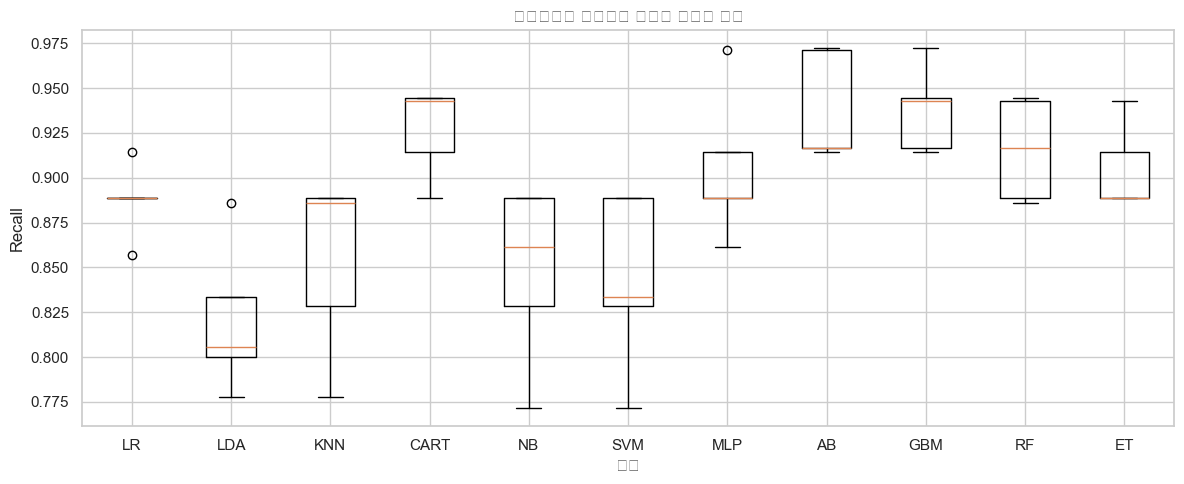

In [21]:
# 모델별 재현율 분포 시각화
plt.figure(figsize=(12, 5))
plt.boxplot(balanced_results, tick_labels=balanced_names)
plt.title("언더샘플링 데이터의 모델별 재현율 비교")
plt.xlabel("모델")
plt.ylabel("Recall")
plt.tight_layout()
plt.show()

## 10. Gradient Boosting 하이퍼파라미터 튜닝

Gradient Boosting의 트리 깊이(`max_depth`)와 추정기 개수(`n_estimators`)를 탐색합니다. 교차검증은 언더샘플링된 학습 데이터 안에서만 수행합니다.

In [22]:
# 탐색할 하이퍼파라미터 범위
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [2, 3]
}

gbm = GradientBoostingClassifier(random_state=seed)

grid_search = GridSearchCV(
    estimator=gbm,
    param_grid=param_grid,
    scoring="recall",
    cv=balanced_kfold,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_balanced, y_train_balanced)

print("최적 재현율:", grid_search.best_score_)
print("최적 하이퍼파라미터:", grid_search.best_params_)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
최적 재현율: 0.9380952380952381
최적 하이퍼파라미터: {'max_depth': 3, 'n_estimators': 50}


In [23]:
# 모든 하이퍼파라미터 조합의 평가 결과 확인
grid_results = pd.DataFrame(grid_search.cv_results_)

display(
    grid_results[
        [
            "rank_test_score",
            "mean_test_score",
            "std_test_score",
            "params"
        ]
    ].sort_values("rank_test_score")
)

,rank_test_score,mean_test_score,std_test_score,params
3,1,0.938,0.021,"{'max_depth': 3, 'n_estimators': 50}"
4,1,0.938,0.021,"{'max_depth': 3, 'n_estimators': 100}"
1,3,0.932,0.029,"{'max_depth': 2, 'n_estimators': 100}"
0,3,0.932,0.029,"{'max_depth': 2, 'n_estimators': 50}"
5,5,0.927,0.014,"{'max_depth': 3, 'n_estimators': 200}"
2,6,0.927,0.039,"{'max_depth': 2, 'n_estimators': 200}"


## 11. 최종 모델 평가



In [24]:
# GridSearchCV에서 찾은 최적 모델 사용
best_model = grid_search.best_estimator_

# 원본 검증 데이터 예측
final_predictions = best_model.predict(X_validation)

# 주요 평가 지표 출력
print("정확도(Accuracy):", accuracy_score(y_validation, final_predictions))
print("정밀도(Precision):", precision_score(y_validation, final_predictions, zero_division=0))
print("재현율(Recall):", recall_score(y_validation, final_predictions, zero_division=0))
print("F1 점수:", f1_score(y_validation, final_predictions, zero_division=0))

print("\n분류 보고서:")
print(classification_report(
    y_validation,
    final_predictions,
    target_names=["정상 거래", "사기 거래"],
    zero_division=0
))

정확도(Accuracy): 0.9367
정밀도(Precision): 0.034324942791762014
재현율(Recall): 1.0
F1 점수: 0.06637168141592921

분류 보고서:
              precision    recall  f1-score   support

       정상 거래       1.00      0.94      0.97     19955
       사기 거래       0.03      1.00      0.07        45

    accuracy                           0.94     20000
   macro avg       0.52      0.97      0.52     20000
weighted avg       1.00      0.94      0.97     20000



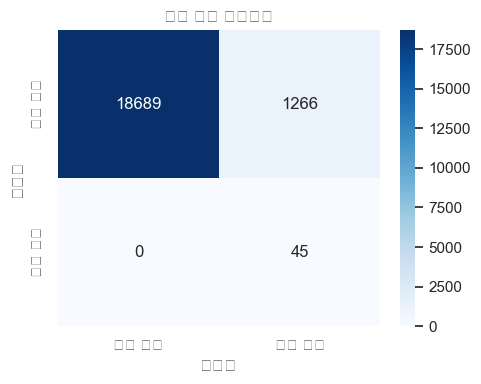

In [25]:
# 최종 모델 혼동행렬
final_cm = confusion_matrix(y_validation, final_predictions)

plt.figure(figsize=(5, 4))
sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["정상 예측", "사기 예측"],
    yticklabels=["실제 정상", "실제 사기"]
)
plt.title("최종 모델 혼동행렬")
plt.xlabel("예측값")
plt.ylabel("실제값")
plt.tight_layout()
plt.show()